# A Practical Overview of Seaborn Plots

This notebook demonstrates current Seaborn distribution, relationship, categorical, and count plots with one deterministic customer fixture. Each chart answers a different question; the goal is not to use every chart at once.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_SEED = 73
OUTPUT_DIR = Path('generated/visualization-073')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
rows = 360
segments = rng.choice(['Value', 'Core', 'Premium'], size=rows, p=[0.35, 0.45, 0.20])
age = np.clip(rng.normal(42, 13, rows), 18, 82)
visits = rng.poisson(np.where(segments == 'Premium', 8, np.where(segments == 'Core', 5, 3)))
spend = np.maximum(10, 18 + visits * 11 + (segments == 'Premium') * 55 + rng.normal(0, 24, rows))
customers = pd.DataFrame({'segment': segments, 'age': age, 'monthly_visits': visits, 'monthly_spend': spend})
sns.set_theme(style='whitegrid', context='notebook')
customers.head()

,segment,age,monthly_visits,monthly_spend
0,Core,31.527059,3,54.061706
1,Value,41.855936,7,90.472010
2,Value,38.735220,6,68.113414
3,Premium,32.538722,10,193.918215
4,Value,41.236843,5,33.673951


## 1. Choose a Plot for the Question

Histograms show distributions, scatterplots show relationships, boxplots compare distributions across categories, and count plots show category frequency.

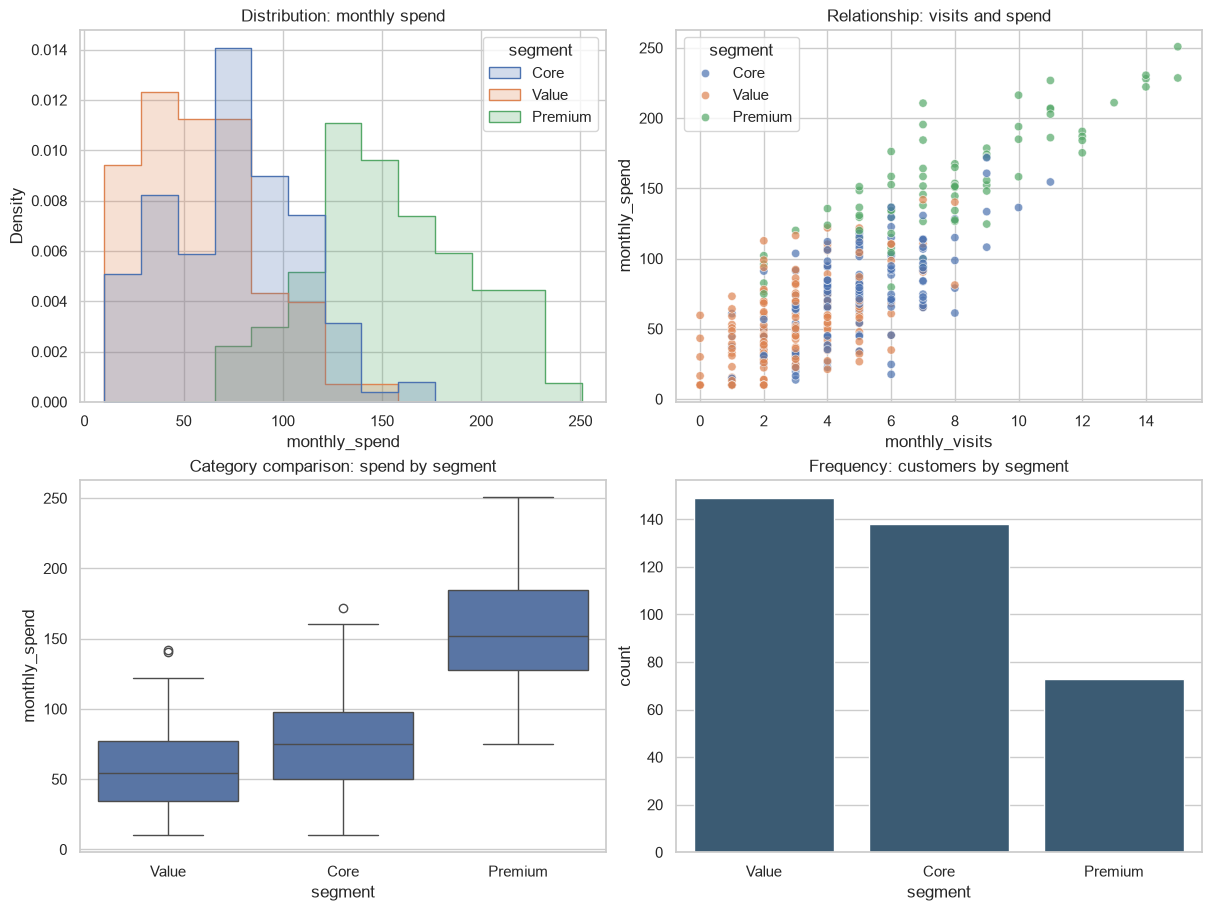

saved: generated\visualization-073\seaborn-plot-overview.png


In [2]:
figure, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
sns.histplot(data=customers, x='monthly_spend', hue='segment', element='step', stat='density', common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title('Distribution: monthly spend')
sns.scatterplot(data=customers, x='monthly_visits', y='monthly_spend', hue='segment', alpha=0.7, ax=axes[0, 1])
axes[0, 1].set_title('Relationship: visits and spend')
sns.boxplot(data=customers, x='segment', y='monthly_spend', order=['Value', 'Core', 'Premium'], ax=axes[1, 0])
axes[1, 0].set_title('Category comparison: spend by segment')
sns.countplot(data=customers, x='segment', order=['Value', 'Core', 'Premium'], color='#315c7d', ax=axes[1, 1])
axes[1, 1].set_title('Frequency: customers by segment')
figure_path = OUTPUT_DIR / 'seaborn-plot-overview.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')

## 2. Interpretation Checklist

- Label axes and units.
- Show uncertainty or raw observations when summaries may hide variation.
- Avoid truncated axes that exaggerate differences.
- Check whether hue, ordering, and aggregation match the question.
- Treat visual association as evidence to investigate, not proof of causation.